In [1]:
import time, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from tqdm.auto import tqdm

from sklearn.model_selection import KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import Ridge, ElasticNet
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("Libraries imported.")

Libraries imported.


In [6]:

import pandas as pd
import os

# Load your existing diamonds.csv file
df = pd.read_csv("diamonds.csv")

# Display dataset information
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

# Display the first five rows
display(df.head())

Dataset shape: (53940, 10)

Column names: ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [8]:
df.info()
print("\nMissing values per column:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
display(df.describe().T)


<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.7 MB

Missing values per column:
 carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

Duplicate rows: 146


,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


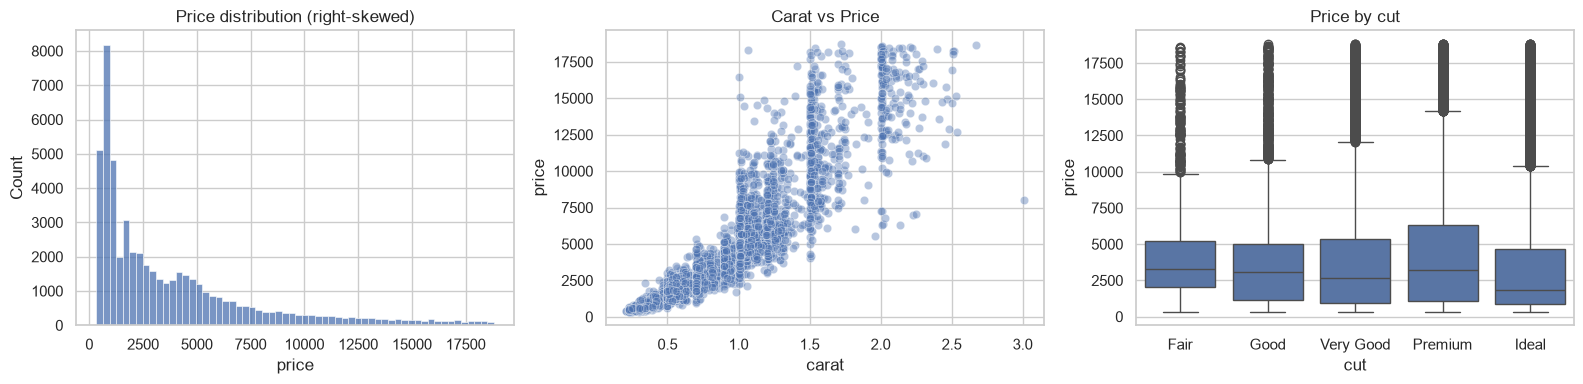

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["price"], bins=60, ax=ax[0]);  ax[0].set_title("Price distribution (right-skewed)")
sns.scatterplot(data=df.sample(5000, random_state=1), x="carat", y="price", alpha=.4, ax=ax[1]); ax[1].set_title("Carat vs Price")
sns.boxplot(data=df, x="cut", y="price", order=["Fair","Good","Very Good","Premium","Ideal"], ax=ax[2]); ax[2].set_title("Price by cut")
plt.tight_layout(); plt.show()

In [10]:
bad = (df[["x", "y", "z"]] == 0).any(axis=1) | (df["y"] > 30) | (df["z"] > 30)
print(f"Rows removed as invalid: {bad.sum()}  ({bad.mean()*100:.3f}% of the data)")
df = df[~bad].reset_index(drop=True)
print("Shape after cleaning:", df.shape)

Rows removed as invalid: 23  (0.043% of the data)
Shape after cleaning: (53917, 10)


In [11]:
TARGET = "price"
cut_order     = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
color_order   = ["J", "I", "H", "G", "F", "E", "D"]               # J (worst) -> D (best)
clarity_order = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

cat_cols = ["cut", "color", "clarity"]
num_cols = ["carat", "depth", "table", "x", "y", "z"]

X = df[num_cols + cat_cols]
y = df[TARGET].values

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OrdinalEncoder(categories=[cut_order, color_order, clarity_order]), cat_cols),
    ])

def make_pipeline(estimator):
    reg = TransformedTargetRegressor(regressor=estimator, func=np.log1p, inverse_func=np.expm1)
    return Pipeline([("prep", make_preprocessor()), ("model", reg)])

print("Features:", list(X.columns), "| Samples:", len(X))

Features: ['carat', 'depth', 'table', 'x', 'y', 'z', 'cut', 'color', 'clarity'] | Samples: 53917


In [12]:
models = {
    "Ridge Regression":        Ridge(alpha=1.0),
    "ElasticNet Regression":   ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=5000),
    "Extra Trees":             ExtraTreesRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting":  HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=RANDOM_STATE),
    "MLP Neural Network":      MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200, random_state=RANDOM_STATE),
}
print(list(models))

['Ridge Regression', 'ElasticNet Regression', 'Extra Trees', 'Hist Gradient Boosting', 'MLP Neural Network']


In [13]:
K = 10
kf = KFold(n_splits=K, shuffle=True, random_state=RANDOM_STATE)

records = []
total_steps = len(models) * K
with tqdm(total=total_steps, desc="Cross-validation", unit="fit") as bar:
    for name, est in models.items():
        for fold, (tr, te) in enumerate(kf.split(X), start=1):
            bar.set_postfix_str(f"{name} | fold {fold}/{K}")
            pipe = make_pipeline(est)
            t0 = time.time()
            pipe.fit(X.iloc[tr], y[tr])
            fit_time = time.time() - t0
            pred = pipe.predict(X.iloc[te])
            records.append({
                "Model": name, "Fold": fold,
                "RMSE": np.sqrt(mean_squared_error(y[te], pred)),
                "MAE":  mean_absolute_error(y[te], pred),
                "R2":   r2_score(y[te], pred),
                "Fit time (s)": fit_time,
            })
            bar.update(1)

cv_results = pd.DataFrame(records)
print("Done.")

Cross-validation:   0%|          | 0/50 [00:00<?, ?fit/s]

Done.


In [14]:
summary = (cv_results.groupby("Model")
           .agg(RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
                MAE_mean=("MAE", "mean"), R2_mean=("R2", "mean"),
                Avg_fit_time_s=("Fit time (s)", "mean"))
           .sort_values("RMSE_mean").round(3))
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary

,Rank,RMSE_mean,RMSE_std,MAE_mean,R2_mean,Avg_fit_time_s
Model,,,,,,
Extra Trees,1,530.760,22.217,266.665,0.982,2.416
Hist Gradient Boosting,2,531.234,20.957,266.938,0.982,3.156
MLP Neural Network,3,622.601,58.804,316.556,0.975,31.649
Ridge Regression,4,893.598,35.637,462.910,0.950,0.198
ElasticNet Regression,5,909.489,40.030,464.676,0.948,0.531


In [15]:
fold_table = cv_results.pivot(index="Fold", columns="Model", values="RMSE").round(1)
fold_table.loc["Mean"] = fold_table.mean().round(1)
fold_table

Model,ElasticNet Regression,Extra Trees,Hist Gradient Boosting,MLP Neural Network,Ridge Regression
Fold,,,,,
1,838.6,493.5,497.1,553.0,832.3
2,916.9,532.8,532.2,634.1,900.1
3,903.0,497.0,503.4,557.7,882.4
4,880.1,549.4,539.8,587.2,872.6
5,930.3,551.8,564.7,690.6,912.9
6,941.1,528.2,518.5,568.8,920.3
7,885.0,554.3,550.9,619.2,866.4
8,930.3,515.5,528.6,733.0,918.0
9,886.5,537.8,529.8,652.7,872.6


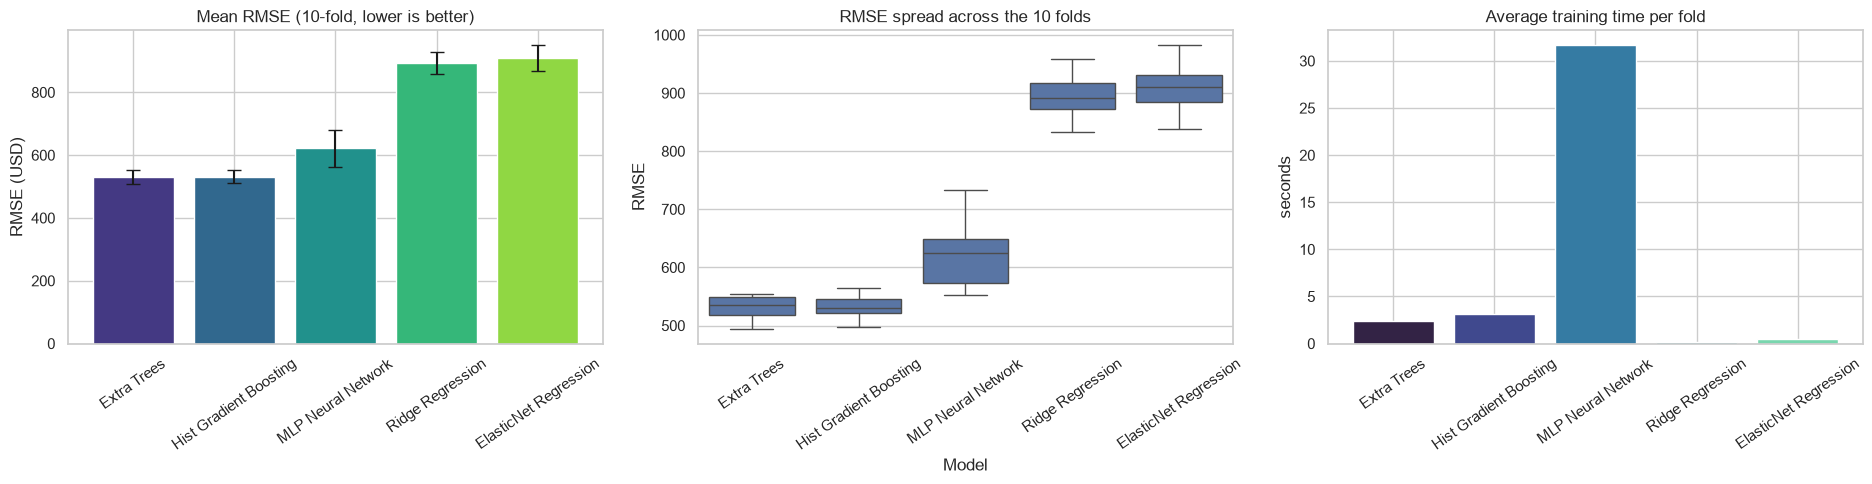

In [16]:
order = summary.index.tolist()
fig, ax = plt.subplots(1, 3, figsize=(19, 5))

ax[0].bar(order, summary["RMSE_mean"], yerr=summary["RMSE_std"], capsize=5, color=sns.color_palette("viridis", len(order)))
ax[0].set_title("Mean RMSE (10-fold, lower is better)"); ax[0].set_ylabel("RMSE (USD)")
ax[0].tick_params(axis="x", rotation=35)

sns.boxplot(data=cv_results, x="Model", y="RMSE", order=order, ax=ax[1])
ax[1].set_title("RMSE spread across the 10 folds"); ax[1].tick_params(axis="x", rotation=35)

ax[2].bar(order, summary["Avg_fit_time_s"], color=sns.color_palette("mako", len(order)))
ax[2].set_title("Average training time per fold"); ax[2].set_ylabel("seconds")
ax[2].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

In [17]:
best_name = summary.index[0]
print(f"Best model by mean RMSE: {best_name}")
print(f"  RMSE = {summary.loc[best_name,'RMSE_mean']:.1f} USD (+/- {summary.loc[best_name,'RMSE_std']:.1f}),  R2 = {summary.loc[best_name,'R2_mean']:.4f}")
print(f"Worst model: {summary.index[-1]} with RMSE = {summary['RMSE_mean'].iloc[-1]:.1f} USD")

Best model by mean RMSE: Extra Trees
  RMSE = 530.8 USD (+/- 22.2),  R2 = 0.9820
Worst model: ElasticNet Regression with RMSE = 909.5 USD


In [18]:
# Train the selected model on all cleaned data and save it to a writable folder
from pathlib import Path

best_pipeline = make_pipeline(models[best_name])
best_pipeline.fit(X, y)

output_dir = Path.home() / "Documents" / "DiamondPriceAssignment"
output_dir.mkdir(parents=True, exist_ok=True)
model_path = output_dir / "diamond_price_model.joblib"
joblib.dump(best_pipeline, model_path, compress=3)
size_mb = model_path.stat().st_size / 1e6
print(f"Saved model to: {model_path} ({size_mb:.1f} MB) | Model: {best_name}")
import sklearn
print("scikit-learn version used for training:", sklearn.__version__)
if size_mb > 90:
    print("WARNING: GitHub may reject files above 100 MB. Consider a smaller model for deployment.")


Saved model to: C:\Users\Areeba\Documents\DiamondPriceAssignment\diamond_price_model.joblib (37.8 MB) | Model: Extra Trees
scikit-learn version used for training: 1.9.0


In [19]:
# Quick sanity check: load the saved model and predict one example
loaded = joblib.load(model_path)
sample = pd.DataFrame([{
    "carat": 0.9, "depth": 61.5, "table": 57.0,
    "x": 6.1, "y": 6.15, "z": 3.78,
    "cut": "Ideal", "color": "G", "clarity": "VS2"
}])
print(f"Predicted price: ${loaded.predict(sample)[0]:,.0f}")


Predicted price: $4,424


In [20]:
# Optional: show where your saved model is. The CSV is your existing file, so this notebook does not overwrite it.
print("Model file:", model_path)
print("Original CSV file:", csv_path)


Model file: C:\Users\Areeba\Documents\DiamondPriceAssignment\diamond_price_model.joblib
Original CSV file: C:/Users/Areeba/Downloads/diamonds.csv
